In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import OrdinalEncoder
import os
import pandas as pd
from scipy.spatial.distance import cdist # For de-embedding reference

In [7]:
# Load the data
x_cat_train = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/X_cat_train.npy', allow_pickle=True)
x_num_train = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/X_num_train.npy', allow_pickle=True)
y_train = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/y_train.npy', allow_pickle=True)

x_cat_test = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/X_cat_test.npy', allow_pickle=True)
x_num_test = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/X_num_test.npy', allow_pickle=True)
y_test = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/y_test.npy', allow_pickle=True)

x_cat_val = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/X_cat_val.npy', allow_pickle=True)
x_num_val = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/X_num_val.npy', allow_pickle=True)
y_val = np.load('/home/fjunpop/tab-ddpm-dp/data/churn2/y_val.npy', allow_pickle=True)

# Get unique values

# 1. Unique values across all categorical features in the training set
print("--- Unique values in x_cat_train (across all columns) ---")
unique_x_cat_train = np.unique(x_cat_train)
print(unique_x_cat_train)

print("\n--- Unique values per categorical feature (column) in x_cat_train ---")
# Iterate through each column (feature) of the 2D array
for i in range(x_cat_train.shape[1]):
    # Slice the array to get all rows for the i-th column: x_cat_train[:, i]
    unique_col_i = np.unique(x_cat_train[:, i])
    print(f"Feature {i} (Cat_{i}): {len(unique_col_i)} unique IDs -> {unique_col_i}")

print("\n--- Unique values in y_train (class labels) ---")
# The target variable usually contains the class labels (e.g., [0, 1] for binary classification)
unique_y_train = np.unique(y_train)
print(unique_y_train)

print(x_num_train[:5])
print(x_cat_train[:5])

# print(x_cat_train.shape)
# print(x_num_train.shape)
# print(y_train.shape)

--- Unique values in x_cat_train (across all columns) ---
['0' '1' 'France' 'Germany' 'Spain']

--- Unique values per categorical feature (column) in x_cat_train ---
Feature 0 (Cat_0): 3 unique IDs -> ['France' 'Germany' 'Spain']
Feature 1 (Cat_1): 2 unique IDs -> ['0' '1']
Feature 2 (Cat_2): 2 unique IDs -> ['0' '1']
Feature 3 (Cat_3): 2 unique IDs -> ['0' '1']

--- Unique values in y_train (class labels) ---
[0 1]
[[8.3800000e+02 3.5000000e+01 0.0000000e+00 0.0000000e+00 2.0000000e+00
  1.9730591e+05 1.9730591e+05]
 [6.6100000e+02 4.4000000e+01 1.0000000e+00 1.4113662e+05 1.0000000e+00
  1.8974278e+05 1.8974278e+05]
 [5.4700000e+02 6.2000000e+01 1.0000000e+01 1.2773875e+05 2.0000000e+00
  8.5153000e+04 8.5153000e+04]
 [6.1500000e+02 4.1000000e+01 4.0000000e+00 1.3038582e+05 1.0000000e+00
  1.3066195e+05 1.3066195e+05]
 [7.2100000e+02 4.0000000e+01 3.0000000e+00 0.0000000e+00 1.0000000e+00
  1.4487467e+05 1.4487467e+05]]
[['Spain' '1' '0' '1']
 ['Germany' '1' '1' '0']
 ['France' '1' '

### Encode into  Latent Representation

In [14]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

torch.manual_seed(42)
np.random.seed(42)

BASE_PATH = '/home/fjunpop/tab-ddpm-dp/data/churn2/'
OUTPUT_DIR = '/home/fjunpop/tab-ddpm-dp/data/churn2lat/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# LOAD DATA (RAW)
# ============================================================

x_cat_train = np.load(os.path.join(BASE_PATH, 'X_cat_train.npy'), allow_pickle=True)
x_num_train = np.load(os.path.join(BASE_PATH, 'X_num_train.npy'), allow_pickle=True)
y_train = np.load(os.path.join(BASE_PATH, 'y_train.npy'), allow_pickle=True)

x_cat_val = np.load(os.path.join(BASE_PATH, 'X_cat_val.npy'), allow_pickle=True)
x_num_val = np.load(os.path.join(BASE_PATH, 'X_num_val.npy'), allow_pickle=True)
y_val = np.load(os.path.join(BASE_PATH, 'y_val.npy'), allow_pickle=True)

x_cat_test = np.load(os.path.join(BASE_PATH, 'X_cat_test.npy'), allow_pickle=True)
x_num_test = np.load(os.path.join(BASE_PATH, 'X_num_test.npy'), allow_pickle=True)
y_test = np.load(os.path.join(BASE_PATH, 'y_test.npy'), allow_pickle=True)

# ============================================================
# ENCODE CATEGORICAL (column 0 = country, fit on all splits
# so unseen-in-train categories in val/test still map cleanly)
# ============================================================

country_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

country_encoder.fit(np.vstack([
    x_cat_train[:, 0:1],
    x_cat_val[:, 0:1],
    x_cat_test[:, 0:1]
]))

def encode_cat(x_cat):
    x = x_cat.copy()
    x[:, 0:1] = country_encoder.transform(x[:, 0:1])
    # FORCE all columns to numeric safely (handles '2.0', '1', '0', etc.)
    x = x.astype(str)
    x = x.astype(float).astype(np.int64)
    return x

x_cat_train = encode_cat(x_cat_train)
x_cat_val = encode_cat(x_cat_val)
x_cat_test = encode_cat(x_cat_test)

# ============================================================
# SCALE NUMERIC FEATURES (fit on train only, applied to all)
# This matters because the AE trains on raw MSE — without scaling,
# large-magnitude columns (Balance, EstimatedSalary) dominate the
# loss and small-magnitude columns (Age, CreditScore) reconstruct
# poorly. TabDDPM's own quantile transform is applied later to the
# *exported latents*, not to these raw features, so it doesn't
# substitute for this step.
# ============================================================

num_scaler = StandardScaler()
x_num_train = num_scaler.fit_transform(x_num_train).astype(np.float32)
x_num_val = num_scaler.transform(x_num_val).astype(np.float32)
x_num_test = num_scaler.transform(x_num_test).astype(np.float32)

y_train = y_train.astype(np.float32)
y_val = y_val.astype(np.float32)
y_test = y_test.astype(np.float32)

# ============================================================
# MODEL CONFIG
# ============================================================

C_cat = x_cat_train.shape[1]
C_num = x_num_train.shape[1]

# cat_dims must reflect everything the encoder can produce across
# ALL splits (country_encoder was fit on train+val+test), not just
# train, or you'll get an out-of-range embedding index later.
cat_dims = [len(country_encoder.categories_[0])] + [
    int(max(x_cat_train[:, i].max(), x_cat_val[:, i].max(), x_cat_test[:, i].max()) + 1)
    for i in range(1, C_cat)
]
# Binary columns only need 1-2 dims; country gets a bit more room.
embed_dims = [3] + [1] * (C_cat - 1)
LATENT_DIM = 12

# ============================================================
# MODEL
# ============================================================

class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(c, e) for c, e in zip(cat_dims, embed_dims)
        ])

        self.encoder = nn.Sequential(
            nn.Linear(C_num + sum(embed_dims), 64),
            nn.ReLU(),
            nn.Linear(64, LATENT_DIM)
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, 64),
            nn.ReLU()
        )

        self.num_head = nn.Linear(64, C_num)

        self.cat_heads = nn.ModuleList([
            nn.Linear(64, c) for c in cat_dims
        ])

    def encode(self, x_cat, x_num):
        embs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat([x_num] + embs, dim=1)
        return self.encoder(x)

    def decode(self, z):
        h = self.decoder(z)
        return self.num_head(h), [head(h) for head in self.cat_heads]

    def forward(self, x_cat, x_num):
        z = self.encode(x_cat, x_num)
        return z

model = AutoEncoder()
optimizer = optim.Adam(model.parameters(), lr=3e-3)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(x_cat_train).long(),
        torch.tensor(x_num_train).float()
    ),
    batch_size=64,
    shuffle=True
)

# ============================================================
# TRAIN (true self-supervised reconstruction)
# ============================================================
num_criterion = nn.MSELoss()
cat_criterion = nn.CrossEntropyLoss()

best_val_loss = float('inf')
best_state_dict = None

import copy

epochs = 50
model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_cat, batch_num in train_loader:
        optimizer.zero_grad()
        z = model.encode(batch_cat, batch_num)
        recon_num, recon_cats = model.decode(z)
        loss_num = num_criterion(recon_num, batch_num)
        loss_cat = sum(cat_criterion(recon_cats[i], batch_cat[:, i]) for i in range(C_cat))
        total_loss = loss_num + loss_cat
        total_loss.backward()
        optimizer.step()
        epoch_loss += total_loss.item()

    model.eval()
    with torch.no_grad():
        z_v = model.encode(torch.tensor(x_cat_val).long(), torch.tensor(x_num_val).float())
        rv, cv = model.decode(z_v)
        val_loss = num_criterion(rv, torch.tensor(x_num_val).float()).item()
    model.train()

    print(f"... | Val recon loss: {val_loss:.4f}")
    print(f"Epoch {epoch+1}/{epochs} | Reconstruction Loss: {epoch_loss/len(train_loader):.4f}")

    # Track the best checkpoint seen so far
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state_dict = copy.deepcopy(model.state_dict())
        print(f"  ↳ New best val loss: {best_val_loss:.4f} (saved checkpoint)")

print("✔ Autoencoder converged.\n")

# Restore the best checkpoint before doing anything else with the model
model.load_state_dict(best_state_dict)
print(f"Restored best checkpoint (val loss = {best_val_loss:.4f})\n")

# ============================================================
# SANITY CHECK: round-trip val set before trusting the latents
# ============================================================

model.eval()
with torch.no_grad():
    z_val = model.encode(torch.tensor(x_cat_val).long(), torch.tensor(x_num_val).float())
    num_out_val, cat_out_val = model.decode(z_val)

    num_mae = np.abs(num_out_val.numpy() - x_num_val).mean(axis=0)
    cat_acc = [
        (cat_out_val[i].argmax(1).numpy() == x_cat_val[:, i]).mean()
        for i in range(C_cat)
    ]

print("Val numeric MAE per column (scaled units):", num_mae)
print("Val categorical accuracy per column:", cat_acc)
print()

# ============================================================
# EXPORT LATENTS
# ============================================================

def get_latent(x_cat, x_num):
    with torch.no_grad():
        return model.encode(
            torch.tensor(x_cat).long(),
            torch.tensor(x_num).float()
        ).numpy()

X_train_latent = get_latent(x_cat_train, x_num_train)
X_val_latent = get_latent(x_cat_val, x_num_val)
X_test_latent = get_latent(x_cat_test, x_num_test)

np.save(os.path.join(OUTPUT_DIR, 'X_num_train.npy'), X_train_latent)
np.save(os.path.join(OUTPUT_DIR, 'X_num_val.npy'), X_val_latent)
np.save(os.path.join(OUTPUT_DIR, 'X_num_test.npy'), X_test_latent)

np.save(os.path.join(OUTPUT_DIR, 'y_train.npy'), y_train)
np.save(os.path.join(OUTPUT_DIR, 'y_val.npy'), y_val)
np.save(os.path.join(OUTPUT_DIR, 'y_test.npy'), y_test)

# SAVE EVERYTHING REQUIRED FOR DECODING
torch.save({
    'model_state_dict': model.state_dict(),
    'cat_dims': cat_dims,
    'embed_dims': embed_dims,
    'num_features': C_num,
    'latent_dim': LATENT_DIM,
    'country_encoder': country_encoder,
    'num_scaler': num_scaler,
}, os.path.join(OUTPUT_DIR, 'encoder.pt'))

print("✔ Encoding complete → ready for TabDDPM")

... | Val recon loss: 0.1044
Epoch 1/50 | Reconstruction Loss: 2.4345
  ↳ New best val loss: 0.1044 (saved checkpoint)
... | Val recon loss: 0.0418
Epoch 2/50 | Reconstruction Loss: 0.2459
  ↳ New best val loss: 0.0418 (saved checkpoint)
... | Val recon loss: 0.0170
Epoch 3/50 | Reconstruction Loss: 0.0292
  ↳ New best val loss: 0.0170 (saved checkpoint)
... | Val recon loss: 0.0099
Epoch 4/50 | Reconstruction Loss: 0.0151
  ↳ New best val loss: 0.0099 (saved checkpoint)
... | Val recon loss: 0.0078
Epoch 5/50 | Reconstruction Loss: 0.0109
  ↳ New best val loss: 0.0078 (saved checkpoint)
... | Val recon loss: 0.0068
Epoch 6/50 | Reconstruction Loss: 0.0084
  ↳ New best val loss: 0.0068 (saved checkpoint)
... | Val recon loss: 0.0058
Epoch 7/50 | Reconstruction Loss: 0.0068
  ↳ New best val loss: 0.0058 (saved checkpoint)
... | Val recon loss: 0.0037
Epoch 8/50 | Reconstruction Loss: 0.0057
  ↳ New best val loss: 0.0037 (saved checkpoint)
... | Val recon loss: 0.0041
Epoch 9/50 | Recons

### Decode Synthetic Latents Back to Features - for eps 100/10/1

In [10]:
import os
import numpy as np
import torch
import torch.nn as nn

# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/ddpm_cb_best'
# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_100_best'
# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_10_best'
SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_5_best'
# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_1_best'
OUT_DIR = os.path.join(SYN_DIR, 'reverted')
os.makedirs(OUT_DIR, exist_ok=True)

LATENT_DIR = '/home/fjunpop/tab-ddpm-dp/data/churn2lat/'

# ============================================================
# LOAD SYNTHETIC LATENTS
# ============================================================

z_syn = np.load(os.path.join(SYN_DIR, 'X_num_train.npy'), allow_pickle=True)
y_syn = np.load(os.path.join(SYN_DIR, 'y_train.npy'), allow_pickle=True)

# ============================================================
# LOAD ENCODER ARTIFACTS
# ============================================================

ckpt = torch.load(os.path.join(LATENT_DIR, 'encoder.pt'), map_location='cpu')
cat_dims = ckpt['cat_dims']
embed_dims = ckpt['embed_dims']
C_num = ckpt['num_features']
LATENT_DIM = ckpt['latent_dim']
country_encoder = ckpt['country_encoder']
num_scaler = ckpt['num_scaler']

# ============================================================
# MODEL (same architecture)
# ============================================================

class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(c, e) for c, e in zip(cat_dims, embed_dims)
        ])
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, 64),
            nn.ReLU()
        )
        self.num_head = nn.Linear(64, C_num)
        self.cat_heads = nn.ModuleList([
            nn.Linear(64, c) for c in cat_dims
        ])

    def decode(self, z):
        h = self.decoder(z)
        return self.num_head(h), [head(h) for head in self.cat_heads]

model = AutoEncoder()
missing = model.load_state_dict(ckpt['model_state_dict'], strict=False)
print(missing)
model.eval()

# ============================================================
# DECODE
# ============================================================

with torch.no_grad():
    z = torch.tensor(z_syn).float()
    num_out, cat_out = model.decode(z)

    # invert the StandardScaler back to original numeric units
    X_num = num_scaler.inverse_transform(num_out.numpy())

    X_cat_ids = np.column_stack([
        h.argmax(1).numpy() for h in cat_out
    ])

X_num[:, 1] = np.clip(X_num[:, 1], 18, 100)  # Age column

# ============================================================
# BACK TO ORIGINAL FORMAT
# ============================================================

X_cat = np.empty(X_cat_ids.shape, dtype=object)

# country back to string
X_cat[:, 0:1] = country_encoder.inverse_transform(X_cat_ids[:, 0:1])

# binary columns already real
for i in range(1, X_cat_ids.shape[1]):
    X_cat[:, i] = X_cat_ids[:, i].astype(str)

# ============================================================
# SAVE
# ============================================================
np.save(os.path.join(OUT_DIR, 'X_num_train.npy'), X_num)
np.save(os.path.join(OUT_DIR, 'X_cat_train.npy'), X_cat)
np.save(os.path.join(OUT_DIR, 'y_train.npy'), y_syn)

print("✔ Reconstruction complete")
print(X_num.shape, X_cat.shape)

_IncompatibleKeys(missing_keys=[], unexpected_keys=['encoder.0.weight', 'encoder.0.bias', 'encoder.2.weight', 'encoder.2.bias'])
✔ Reconstruction complete
(21600, 7) (21600, 4)


### checks numeric distributions (mean/std/quantiles + histograms) and categorical frequency tables side by side.

Real:      6400 rows | Synthetic: 21600 rows

=== Numeric summary (real vs synthetic) ===
       CreditScore | real  mean=      650.65 std=       96.26 p50=      652.00
                   | synth mean=      687.20 std=      172.69 p50=      673.85
               Age | real  mean=       38.87 std=       10.51 p50=       37.00
                   | synth mean=       40.39 std=       18.10 p50=       35.42
            Tenure | real  mean=        5.00 std=        2.88 p50=        5.00
                   | synth mean=        6.25 std=        5.63 p50=        6.23
           Balance | real  mean=    77196.33 std=    62181.62 p50=    97535.75
                   | synth mean=   105555.32 std=    90986.91 p50=   100617.45
     NumOfProducts | real  mean=        1.53 std=        0.58 p50=        1.00
                   | synth mean=        1.91 std=        1.39 p50=        1.71
   EstimatedSalary | real  mean=   100313.03 std=    57638.53 p50=   100770.70
                   | synth mean=   130975

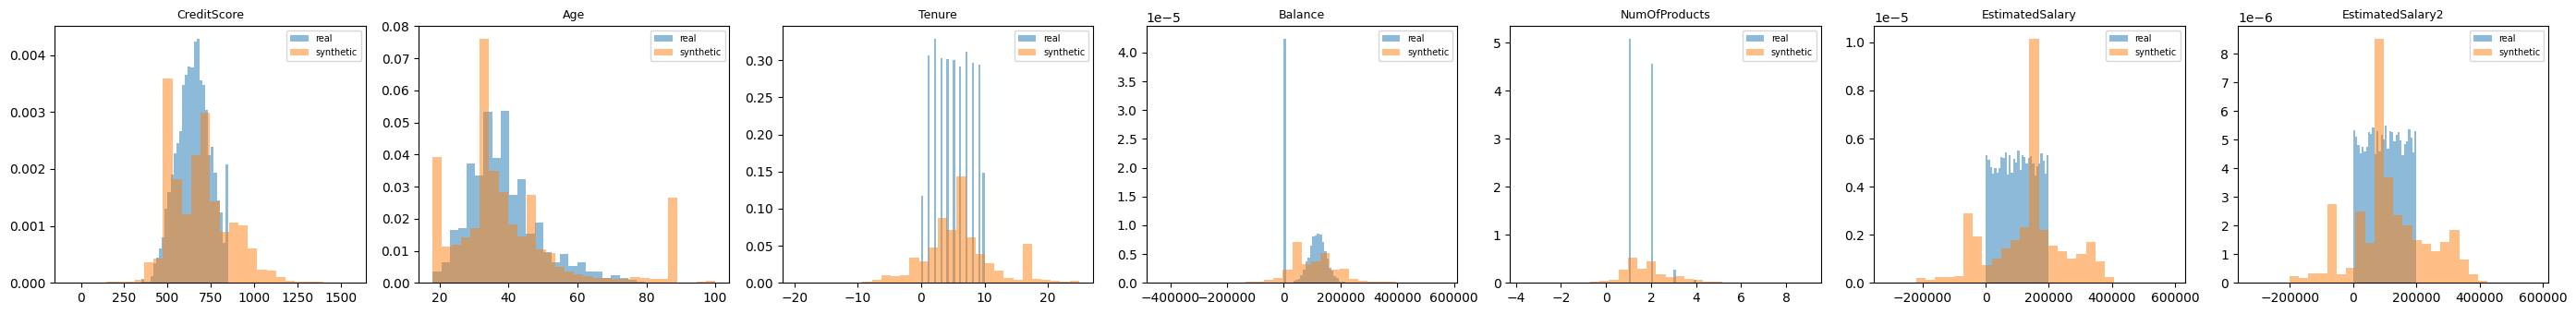


=== Categorical frequencies (real vs synthetic) ===

Country:
      France | real= 49.6%  synthetic= 63.3%
     Germany | real= 25.2%  synthetic= 23.5%
       Spain | real= 25.2%  synthetic= 13.2%

HasCrCard:
           0 | real= 45.5%  synthetic= 61.7%
           1 | real= 54.5%  synthetic= 38.3%

IsActiveMember:
           0 | real= 29.6%  synthetic= 50.3%
           1 | real= 70.4%  synthetic= 49.7%

Exited_flagcol:
           0 | real= 48.0%  synthetic= 34.6%
           1 | real= 52.0%  synthetic= 65.4%

✔ Saved numeric_comparison.png to /home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_10_best/reverted
Synthetic Age min/max: 18.0 100.0
Real Age min/max: 18.0 92.0
Implausible ages: 0 / 21600 (0.0%)


In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt

REAL_DIR = '/home/fjunpop/tab-ddpm-dp/data/churn2/'

# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/ddpm_cb_best'
# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_100_best'
SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_10_best'
# SYN_DIR = '/home/fjunpop/tab-ddpm-dp/exp/churn2lat/churn2lat_dp_eps_1_best'
SYN_REVERTED_DIR = os.path.join(SYN_DIR, 'reverted')

NUM_COLS = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'EstimatedSalary2']
CAT_COLS = ['Country', 'HasCrCard', 'IsActiveMember', 'Exited_flagcol']  # adjust names to match your actual schema

# ============================================================
# LOAD REAL (raw, pre-scaling) AND SYNTHETIC (decoded) DATA
# ============================================================

x_num_real = np.load(os.path.join(REAL_DIR, 'X_num_train.npy'), allow_pickle=True).astype(np.float32)
x_cat_real = np.load(os.path.join(REAL_DIR, 'X_cat_train.npy'), allow_pickle=True)

x_num_syn = np.load(os.path.join(SYN_REVERTED_DIR, 'X_num_train.npy'), allow_pickle=True).astype(np.float32)
x_cat_syn = np.load(os.path.join(SYN_REVERTED_DIR, 'X_cat_train.npy'), allow_pickle=True)

print(f"Real:      {x_num_real.shape[0]} rows | Synthetic: {x_num_syn.shape[0]} rows\n")

# ============================================================
# NUMERIC: SUMMARY STATS + HISTOGRAMS
# ============================================================

C_num = x_num_real.shape[1]
col_names_num = NUM_COLS[:C_num] if len(NUM_COLS) == C_num else [f"num_{i}" for i in range(C_num)]

print("=== Numeric summary (real vs synthetic) ===")
for i, name in enumerate(col_names_num):
    r, s = x_num_real[:, i], x_num_syn[:, i]
    print(f"{name:>18} | real  mean={r.mean():>12.2f} std={r.std():>12.2f} "
          f"p50={np.median(r):>12.2f}")
    print(f"{'':>18} | synth mean={s.mean():>12.2f} std={s.std():>12.2f} "
          f"p50={np.median(s):>12.2f}")

fig, axes = plt.subplots(1, C_num, figsize=(4 * C_num, 3.5))
if C_num == 1:
    axes = [axes]
for i, name in enumerate(col_names_num):
    axes[i].hist(x_num_real[:, i], bins=30, alpha=0.5, label='real', density=True)
    axes[i].hist(x_num_syn[:, i], bins=30, alpha=0.5, label='synthetic', density=True)
    axes[i].set_title(name, fontsize=9)
    axes[i].legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(SYN_REVERTED_DIR, 'numeric_comparison.png'), dpi=120)
plt.show()

# ============================================================
# CATEGORICAL: FREQUENCY TABLES
# ============================================================

C_cat = x_cat_real.shape[1]
col_names_cat = CAT_COLS[:C_cat] if len(CAT_COLS) == C_cat else [f"cat_{i}" for i in range(C_cat)]

print("\n=== Categorical frequencies (real vs synthetic) ===")
for i, name in enumerate(col_names_cat):
    r_vals, r_counts = np.unique(x_cat_real[:, i].astype(str), return_counts=True)
    s_vals, s_counts = np.unique(x_cat_syn[:, i].astype(str), return_counts=True)

    r_freq = dict(zip(r_vals, r_counts / r_counts.sum()))
    s_freq = dict(zip(s_vals, s_counts / s_counts.sum()))

    all_vals = sorted(set(r_freq) | set(s_freq))
    print(f"\n{name}:")
    for v in all_vals:
        print(f"  {v:>10} | real={r_freq.get(v, 0):>6.1%}  synthetic={s_freq.get(v, 0):>6.1%}")

print(f"\n✔ Saved numeric_comparison.png to {SYN_REVERTED_DIR}")

print("Synthetic Age min/max:", x_num_syn[:, 1].min(), x_num_syn[:, 1].max())
print("Real Age min/max:", x_num_real[:, 1].min(), x_num_real[:, 1].max())

# how many synthetic rows are outside a plausible age range, e.g. <18 or >100
bad_age = (x_num_syn[:, 1] < 18) | (x_num_syn[:, 1] > 100)
print(f"Implausible ages: {bad_age.sum()} / {len(x_num_syn)} ({bad_age.mean():.1%})")

In [17]:
print("Synthetic Age min/max:", x_num_syn[:, 1].min(), x_num_syn[:, 1].max())
print("Real Age min/max:", x_num_real[:, 1].min(), x_num_real[:, 1].max())

# how many synthetic rows are outside a plausible age range, e.g. <18 or >100
bad_age = (x_num_syn[:, 1] < 18) | (x_num_syn[:, 1] > 100)
print(f"Implausible ages: {bad_age.sum()} / {len(x_num_syn)} ({bad_age.mean():.1%})")

Synthetic Age min/max: 18.0 100.0
Real Age min/max: 18.0 92.0
Implausible ages: 0 / 21600 (0.0%)


In [7]:
print("Synthetic Age min/max:", x_num_syn[:, 1].min(), x_num_syn[:, 1].max())
bad_age = (x_num_syn[:, 1] < 18) | (x_num_syn[:, 1] > 100)
print(f"Implausible ages: {bad_age.sum()} / {len(x_num_syn)} ({bad_age.mean():.1%})")

Synthetic Age min/max: 18.0 100.0
Implausible ages: 0 / 21600 (0.0%)


In [8]:
at_18 = (X_num[:, 1] == 18).sum()
at_100 = (X_num[:, 1] == 100).sum()
print(f"Pinned at 18: {at_18} ({at_18/len(X_num):.1%})")
print(f"Pinned at 100: {at_100} ({at_100/len(X_num):.1%})")

Pinned at 18: 133 (0.6%)
Pinned at 100: 722 (3.3%)
